# Сравнительный анализ механизмов внимания в графовых нейронных сетях: GAT и GATv2

In [2]:
import json
import os
import random
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torch_geometric.transforms as T
from scipy import stats
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GATConv, GATv2Conv, GCNConv, SAGEConv
from torch_geometric.utils import (coalesce, degree, homophily, remove_self_loops,
                                   to_undirected)

os.makedirs("figures", exist_ok=True)

N_RUNS = 10            # число запусков с разными seed в каждом эксперименте
MAX_EPOCHS = 500       # максимум эпох
PATIENCE = 100         # ранняя остановка: эпох без улучшения валидационной точности
DATA_ROOT = "data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство вычислений: {device}")


def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)


RESULTS = {}  # все числа для РПЗ складываются сюда и сохраняются в results.json

Устройство вычислений: cpu


## 1. Обучающие выборки

Cora, Citeseer, Pubmed — графы цитирования: узел — научная статья, ребро — ссылка между статьями (граф неориентированный), признаки — «мешок слов» по тексту статьи (бинарный для Cora и Citeseer, TF-IDF для Pubmed), метка — тематическая рубрика статьи. Используется стандартное разбиение Planetoid: по 20 размеченных статей на класс для обучения, 500 — для валидации, 1000 — для теста.

In [3]:
CORA_CLASSES = ["Theory", "Reinforcement_Learning", "Genetic_Algorithms", "Neural_Networks",
                "Probabilistic_Methods", "Case_Based", "Rule_Learning"]
DATASETS = ["Cora", "Citeseer", "Pubmed"]
_cache = {}


def load_dataset(name):
    if name not in _cache:
        ds = Planetoid(root=os.path.join(DATA_ROOT, name), name=name,
                       transform=T.NormalizeFeatures())
        data = ds[0]
        data.num_classes = ds.num_classes
        _cache[name] = data
    return _cache[name].clone().to(device)


def describe(name):
    data = load_dataset(name).cpu()
    n, e_dir = data.num_nodes, data.edge_index.size(1)
    deg = degree(data.edge_index[0], num_nodes=n)
    raw = Planetoid(root=os.path.join(DATA_ROOT, name), name=name)[0]  # без нормализации
    info = {
        "nodes": n,
        "directed_edges": e_dir,
        "undirected_edges": e_dir // 2,
        "features": data.num_features,
        "classes": int(data.num_classes),
        "avg_degree": round(deg.mean().item(), 2),
        "max_degree": int(deg.max().item()),
        "isolated_nodes": int((deg == 0).sum().item()),
        "zero_feature_nodes": int((raw.x.abs().sum(1) == 0).sum().item()),
        "binary_features": bool(((raw.x == 0) | (raw.x == 1)).all().item()),
        "avg_words_per_doc": round((raw.x > 0).sum(1).float().mean().item(), 1),
        "train": int(data.train_mask.sum()), "val": int(data.val_mask.sum()),
        "test": int(data.test_mask.sum()),
        "label_rate_%": round(100 * data.train_mask.sum().item() / n, 2),
        "edge_homophily": round(homophily(data.edge_index, data.y, method="edge"), 3),
        "node_homophily": round(homophily(data.edge_index, data.y, method="node"), 3),
        "class_counts": torch.bincount(data.y, minlength=data.num_classes).tolist(),
        "majority_test_acc": round(torch.bincount(data.y[data.test_mask]).max().item() / 1000, 3),
    }
    return info


RESULTS["datasets"] = {}
for name in DATASETS:
    info = describe(name)
    RESULTS["datasets"][name] = info
    print(f"\n=== {name} ===")
    for k, v in info.items():
        print(f"  {k:20s}: {v}")
    if name == "Cora":
        for i, (c, cnt) in enumerate(zip(CORA_CLASSES, info["class_counts"])):
            print(f"    класс {i} {c:24s}: {cnt}")

Processing...
Done!



=== Cora ===
  nodes               : 2708
  directed_edges      : 10556
  undirected_edges    : 5278
  features            : 1433
  classes             : 7
  avg_degree          : 3.9
  max_degree          : 168
  isolated_nodes      : 0
  zero_feature_nodes  : 0
  binary_features     : True
  avg_words_per_doc   : 18.2
  train               : 140
  val                 : 500
  test                : 1000
  label_rate_%        : 5.17
  edge_homophily      : 0.81
  node_homophily      : 0.825
  class_counts        : [351, 217, 418, 818, 426, 298, 180]
  majority_test_acc   : 0.319
    класс 0 Theory                  : 351
    класс 1 Reinforcement_Learning  : 217
    класс 2 Genetic_Algorithms      : 418
    класс 3 Neural_Networks         : 818
    класс 4 Probabilistic_Methods   : 426
    класс 5 Case_Based              : 298
    класс 6 Rule_Learning           : 180


Processing...
Done!



=== Citeseer ===
  nodes               : 3327
  directed_edges      : 9104
  undirected_edges    : 4552
  features            : 3703
  classes             : 6
  avg_degree          : 2.74
  max_degree          : 99
  isolated_nodes      : 48
  zero_feature_nodes  : 15
  binary_features     : True
  avg_words_per_doc   : 31.6
  train               : 120
  val                 : 500
  test                : 1000
  label_rate_%        : 3.61
  edge_homophily      : 0.736
  node_homophily      : 0.706
  class_counts        : [264, 590, 668, 701, 596, 508]
  majority_test_acc   : 0.231



=== Pubmed ===
  nodes               : 19717
  directed_edges      : 88648
  undirected_edges    : 44324
  features            : 500
  classes             : 3
  avg_degree          : 4.5
  max_degree          : 171
  isolated_nodes      : 0
  zero_feature_nodes  : 0
  binary_features     : False
  avg_words_per_doc   : 50.1
  train               : 60
  val                 : 500
  test                : 1000
  label_rate_%        : 0.3
  edge_homophily      : 0.802
  node_homophily      : 0.792
  class_counts        : [4103, 7739, 7875]
  majority_test_acc   : 0.413


Processing...
Done!


## 2. Модели и процедура обучения

In [4]:
class GAT(torch.nn.Module):
    """Двухслойная GAT (Veličković et al., 2018). v2=True — слой GATv2Conv."""

    def __init__(self, in_ch, hidden, out_ch, heads=8, out_heads=1, dropout=0.6, v2=False):
        super().__init__()
        Conv = GATv2Conv if v2 else GATConv
        self.conv1 = Conv(in_ch, hidden, heads=heads, dropout=dropout)
        self.conv2 = Conv(hidden * heads, out_ch, heads=out_heads, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


class GCN(torch.nn.Module):
    def __init__(self, in_ch, hidden, out_ch, dropout=0.5, **_):
        super().__init__()
        self.conv1, self.conv2 = GCNConv(in_ch, hidden), GCNConv(hidden, out_ch)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


class GraphSAGE(torch.nn.Module):
    def __init__(self, in_ch, hidden, out_ch, dropout=0.5, **_):
        super().__init__()
        self.conv1, self.conv2 = SAGEConv(in_ch, hidden), SAGEConv(hidden, out_ch)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


# Гиперпараметры каждой модели — из оригинальных работ
CONFIGS = {
    "GAT":          dict(cls=GAT, hidden=8, heads=8, dropout=0.6, lr=0.005, wd=5e-4, v2=False),
    "GATv2":        dict(cls=GAT, hidden=8, heads=8, dropout=0.6, lr=0.005, wd=5e-4, v2=True),
    "GCN":          dict(cls=GCN, hidden=16, dropout=0.5, lr=0.01, wd=5e-4),
    "GraphSAGE":    dict(cls=GraphSAGE, hidden=16, dropout=0.5, lr=0.01, wd=5e-4),
    "GCN-64":       dict(cls=GCN, hidden=64, dropout=0.5, lr=0.01, wd=5e-4),
    "GraphSAGE-64": dict(cls=GraphSAGE, hidden=64, dropout=0.5, lr=0.01, wd=5e-4),
}
# Для Pubmed в работе GAT использовались 8 выходных голов, lr = 0.01, wd = 0.001
PUBMED_GAT = dict(out_heads=8, lr=0.01, wd=1e-3)


def make_model(model_name, data, dataset_name=None, **override):
    cfg = dict(CONFIGS[model_name])
    if dataset_name == "Pubmed" and model_name in ("GAT", "GATv2"):
        cfg.update(PUBMED_GAT)
    cfg.update(override)
    cls, lr, wd = cfg.pop("cls"), cfg.pop("lr"), cfg.pop("wd")
    model = cls(data.num_features, cfg.pop("hidden"), data.num_classes, **cfg).to(device)
    return model, lr, wd


def train_model(model, data, lr, wd, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    """Обучение с ранней остановкой. Возвращает точность на тесте в эпоху
    с наилучшей валидационной точностью (при равенстве — с меньшей валидационной ошибкой)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    best = dict(val_acc=-1.0, val_loss=float("inf"), test_acc=0.0, epoch=0, state=None)
    bad = 0
    for epoch in range(max_epochs):
        model.train()
        opt.zero_grad()
        out = model(data.x, data.edge_index)
        F.cross_entropy(out[data.train_mask], data.y[data.train_mask]).backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            out = model(data.x, data.edge_index)
            pred = out.argmax(1)
            val_loss = F.cross_entropy(out[data.val_mask], data.y[data.val_mask]).item()
            val_acc = (pred[data.val_mask] == data.y[data.val_mask]).float().mean().item()
            test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
        if val_acc > best["val_acc"] or (val_acc == best["val_acc"] and val_loss < best["val_loss"]):
            best.update(val_acc=val_acc, val_loss=val_loss, test_acc=test_acc, epoch=epoch,
                        state={k: v.detach().clone() for k, v in model.state_dict().items()})
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best["state"])
    model.eval()
    return best


def run(model_name, dataset_name, seeds=range(N_RUNS), data=None, **override):
    data = data if data is not None else load_dataset(dataset_name)
    accs = []
    for s in seeds:
        set_seed(s)
        model, lr, wd = make_model(model_name, data, dataset_name, **override)
        accs.append(train_model(model, data, lr, wd)["test_acc"])
    return accs


def ms(a):
    a = np.asarray(a)
    return f"{a.mean():.4f} ± {a.std(ddof=1):.4f}"


def welch(a, b):
    return stats.ttest_ind(a, b, equal_var=False).pvalue


def summary(a):
    a = np.asarray(a)
    return dict(mean=round(float(a.mean()), 4), std=round(float(a.std(ddof=1)), 4),
                runs=[round(float(x), 4) for x in a])

## Эксперимент 1. GAT и GATv2 на трёх выборках, сравнение с GCN и GraphSAGE

In [5]:
MODELS_MAIN = ["GAT", "GATv2", "GCN", "GraphSAGE", "GCN-64", "GraphSAGE-64"]
RESULTS["main"] = {}
t0 = time.time()
for ds in DATASETS:
    RESULTS["main"][ds] = {}
    print(f"\n=== {ds} ===")
    for m in MODELS_MAIN:
        accs = run(m, ds)
        RESULTS["main"][ds][m] = summary(accs)
        print(f"  {m:13s}: {ms(accs)}   ({time.time() - t0:.0f} c)")

RESULTS["main_pvalues"] = {}
for ds in DATASETS:
    r = {m: RESULTS["main"][ds][m]["runs"] for m in MODELS_MAIN}
    p = {f"{a} vs {b}": round(float(welch(r[a], r[b])), 4)
         for a in ["GAT", "GATv2"] for b in MODELS_MAIN if b != a}
    RESULTS["main_pvalues"][ds] = p
    print(f"\n{ds}: p-значения (Уэлч)")
    for k, v in p.items():
        print(f"  {k:24s}: {v}")


=== Cora ===
  GAT          : 0.8260 ± 0.0108   (127 c)
  GATv2        : 0.8326 ± 0.0057   (333 c)
  GCN          : 0.8203 ± 0.0072   (471 c)
  GraphSAGE    : 0.8136 ± 0.0085   (807 c)
  GCN-64       : 0.8236 ± 0.0061   (949 c)
  GraphSAGE-64 : 0.8104 ± 0.0051   (1166 c)

=== Citeseer ===
  GAT          : 0.7212 ± 0.0072   (1437 c)
  GATv2        : 0.7163 ± 0.0093   (1857 c)
  GCN          : 0.7105 ± 0.0115   (2232 c)
  GraphSAGE    : 0.7056 ± 0.0096   (2949 c)
  GCN-64       : 0.7183 ± 0.0053   (3309 c)
  GraphSAGE-64 : 0.7037 ± 0.0075   (3707 c)

=== Pubmed ===
  GAT          : 0.7810 ± 0.0047   (4508 c)
  GATv2        : 0.7790 ± 0.0029   (5623 c)
  GCN          : 0.7920 ± 0.0043   (6053 c)
  GraphSAGE    : 0.7700 ± 0.0030   (6729 c)
  GCN-64       : 0.7949 ± 0.0028   (7126 c)
  GraphSAGE-64 : 0.7712 ± 0.0061   (7781 c)

Cora: p-значения (Уэлч)
  GAT vs GATv2            : 0.1103
  GAT vs GCN              : 0.1854
  GAT vs GraphSAGE        : 0.011
  GAT vs GCN-64           : 0.5508
 

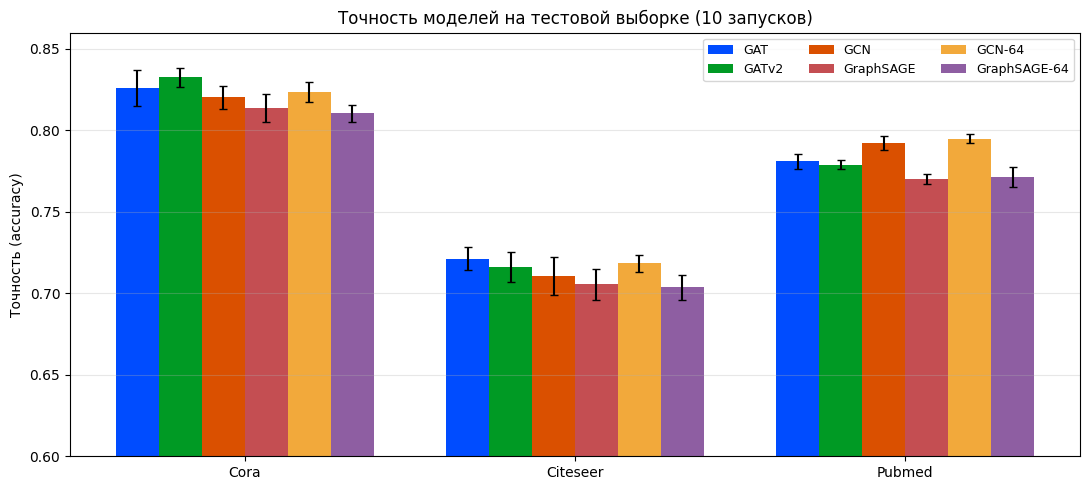

In [6]:
def plot_main():
    fig, ax = plt.subplots(figsize=(11, 5))
    x = np.arange(len(DATASETS))
    w = 0.13
    colors = ["#004CFF", "#009A24", "#DA5000", "#C44E52", "#F2A93B", "#8E5EA2"]
    for i, m in enumerate(MODELS_MAIN):
        means = [RESULTS["main"][d][m]["mean"] for d in DATASETS]
        stds = [RESULTS["main"][d][m]["std"] for d in DATASETS]
        ax.bar(x + (i - 2.5) * w, means, w, yerr=stds, capsize=3, label=m, color=colors[i])
    ax.set_xticks(x)
    ax.set_xticklabels(DATASETS)
    ax.set_ylim(0.6, 0.86)
    ax.set_ylabel("Точность (accuracy)")
    ax.set_title(f"Точность моделей на тестовой выборке ({N_RUNS} запусков)")
    ax.legend(ncol=3, fontsize=9)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig("figures/fig_main_comparison.png", dpi=150)
    plt.show()


plot_main()

## Эксперимент 2. Устойчивость к шуму в рёбрах (Cora)

Случайные рёбра добавляются **симметрично** (в обоих направлениях), петли и дубли удаляются. Доля шума — от числа неориентированных рёбер исходного графа. Для каждого seed генерируется свой шум.

In [7]:
def add_noise_edges(data, ratio, seed):
    if ratio == 0:
        return data.edge_index
    g = torch.Generator().manual_seed(10_000 + seed)
    n = data.num_nodes
    m = int(data.edge_index.size(1) // 2 * ratio)
    src = torch.randint(0, n, (m,), generator=g)
    dst = torch.randint(0, n, (m,), generator=g)
    noise = torch.stack([src, dst]).to(data.edge_index.device)
    ei = torch.cat([data.edge_index, to_undirected(noise)], dim=1)
    ei, _ = remove_self_loops(ei)
    return coalesce(ei, num_nodes=n)


NOISE_LEVELS = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
RESULTS["noise"] = {}
base = load_dataset("Cora")
for lvl in NOISE_LEVELS:
    accs = {"GAT": [], "GATv2": []}
    homs = []
    for s in range(N_RUNS):
        noisy = base.clone()
        noisy.edge_index = add_noise_edges(base, lvl, s)
        homs.append(homophily(noisy.edge_index, noisy.y, method="edge"))
        for m in accs:
            accs[m] += run(m, "Cora", seeds=[s], data=noisy)
    p = welch(accs["GAT"], accs["GATv2"])
    RESULTS["noise"][f"{int(lvl * 100)}%"] = dict(
        GAT=summary(accs["GAT"]), GATv2=summary(accs["GATv2"]),
        edge_homophily=round(float(np.mean(homs)), 3), p_value=round(float(p), 4))
    print(f"шум {lvl * 100:3.0f}%  гомофилия {np.mean(homs):.3f}  "
          f"GAT {ms(accs['GAT'])}  GATv2 {ms(accs['GATv2'])}  p = {p:.3f}")

шум   0%  гомофилия 0.810  GAT 0.8260 ± 0.0108  GATv2 0.8326 ± 0.0057  p = 0.110
шум   5%  гомофилия 0.780  GAT 0.8104 ± 0.0139  GATv2 0.8086 ± 0.0139  p = 0.776
шум  10%  гомофилия 0.754  GAT 0.7968 ± 0.0119  GATv2 0.7978 ± 0.0140  p = 0.866
шум  20%  гомофилия 0.705  GAT 0.7770 ± 0.0112  GATv2 0.7776 ± 0.0091  p = 0.897
шум  30%  гомофилия 0.666  GAT 0.7688 ± 0.0126  GATv2 0.7626 ± 0.0123  p = 0.281
шум  50%  гомофилия 0.600  GAT 0.7440 ± 0.0126  GATv2 0.7296 ± 0.0143  p = 0.028


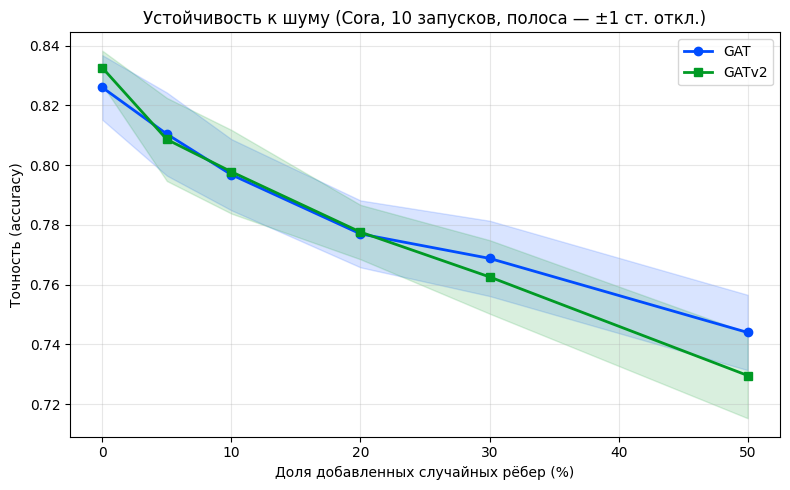

In [8]:
def plot_noise():
    fig, ax = plt.subplots(figsize=(8, 5))
    x = [l * 100 for l in NOISE_LEVELS]
    for m, c, mk in [("GAT", "#004CFF", "o"), ("GATv2", "#009A24", "s")]:
        mean = np.array([RESULTS["noise"][f"{int(l * 100)}%"][m]["mean"] for l in NOISE_LEVELS])
        std = np.array([RESULTS["noise"][f"{int(l * 100)}%"][m]["std"] for l in NOISE_LEVELS])
        ax.plot(x, mean, marker=mk, color=c, label=m, linewidth=2)
        ax.fill_between(x, mean - std, mean + std, color=c, alpha=0.15)
    ax.set_xlabel("Доля добавленных случайных рёбер (%)")
    ax.set_ylabel("Точность (accuracy)")
    ax.set_title(f"Устойчивость к шуму (Cora, {N_RUNS} запусков, полоса — ±1 ст. откл.)")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("figures/fig_noise.png", dpi=150)
    plt.show()


plot_noise()

## Эксперимент 3. Число голов внимания (Cora)

Вариант А: 8 признаков на голову (суммарная размерность и число параметров растут с числом голов).
Вариант Б: суммарная размерность скрытого слоя фиксирована (64), то есть меняется только число голов.

In [9]:
HEADS = [1, 2, 4, 8, 16]
RESULTS["heads"] = {"A_8_per_head": {}, "B_total_64": {}}
for h in HEADS:
    for variant, hidden in [("A_8_per_head", 8), ("B_total_64", 64 // h)]:
        row = {}
        for m in ["GAT", "GATv2"]:
            row[m] = summary(run(m, "Cora", heads=h, hidden=hidden))
        row["p_value"] = round(float(welch(row["GAT"]["runs"], row["GATv2"]["runs"])), 4)
        RESULTS["heads"][variant][h] = row
        print(f"{variant:13s} heads={h:2d} hidden/head={hidden:2d}: "
              f"GAT {row['GAT']['mean']:.4f}±{row['GAT']['std']:.4f}  "
              f"GATv2 {row['GATv2']['mean']:.4f}±{row['GATv2']['std']:.4f}  p={row['p_value']:.3f}")

A_8_per_head  heads= 1 hidden/head= 8: GAT 0.8126±0.0149  GATv2 0.7949±0.0275  p=0.095
B_total_64    heads= 1 hidden/head=64: GAT 0.8275±0.0106  GATv2 0.8156±0.0130  p=0.038
A_8_per_head  heads= 2 hidden/head= 8: GAT 0.8216±0.0083  GATv2 0.8247±0.0140  p=0.556
B_total_64    heads= 2 hidden/head=32: GAT 0.8223±0.0100  GATv2 0.8246±0.0118  p=0.643
A_8_per_head  heads= 4 hidden/head= 8: GAT 0.8248±0.0070  GATv2 0.8307±0.0076  p=0.088
B_total_64    heads= 4 hidden/head=16: GAT 0.8231±0.0081  GATv2 0.8260±0.0075  p=0.418
A_8_per_head  heads= 8 hidden/head= 8: GAT 0.8260±0.0108  GATv2 0.8326±0.0057  p=0.110
B_total_64    heads= 8 hidden/head= 8: GAT 0.8260±0.0108  GATv2 0.8326±0.0057  p=0.110
A_8_per_head  heads=16 hidden/head= 8: GAT 0.8277±0.0059  GATv2 0.8290±0.0072  p=0.664
B_total_64    heads=16 hidden/head= 4: GAT 0.8248±0.0078  GATv2 0.8280±0.0075  p=0.365


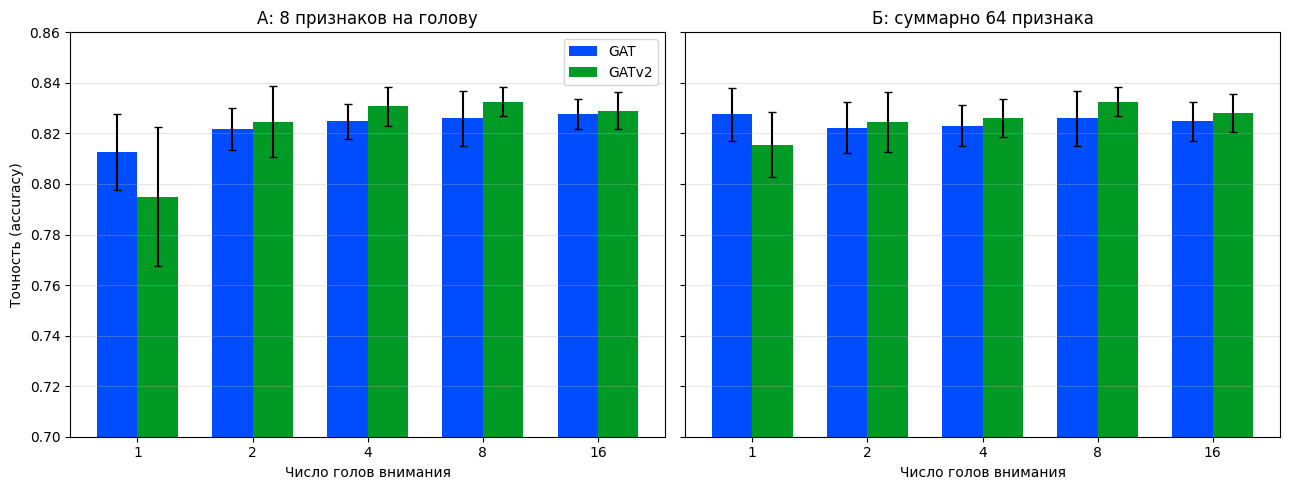

In [10]:
def plot_heads():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    titles = {"A_8_per_head": "А: 8 признаков на голову", "B_total_64": "Б: суммарно 64 признака"}
    for ax, variant in zip(axes, ["A_8_per_head", "B_total_64"]):
        x = np.arange(len(HEADS))
        for i, (m, c) in enumerate([("GAT", "#004CFF"), ("GATv2", "#009A24")]):
            mean = [RESULTS["heads"][variant][h][m]["mean"] for h in HEADS]
            std = [RESULTS["heads"][variant][h][m]["std"] for h in HEADS]
            ax.bar(x + (i - 0.5) * 0.35, mean, 0.35, yerr=std, capsize=3, label=m, color=c)
        ax.set_xticks(x)
        ax.set_xticklabels(HEADS)
        ax.set_xlabel("Число голов внимания")
        ax.set_title(titles[variant])
        ax.set_ylim(0.70, 0.86)
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("Точность (accuracy)")
    axes[0].legend()
    plt.tight_layout()
    plt.savefig("figures/fig_heads.png", dpi=150)
    plt.show()


plot_heads()

## Эксперимент 4. Анализ ошибок по 10 запускам (Cora)

Для каждого seed обучаются GAT и GATv2; сравниваются предсказания на 1000 тестовых узлах. Считаются: таблица совпадений, критерий Мак-Немара, точность по классам и по группам степеней узлов.

In [11]:
data_cora = load_dataset("Cora")
test_idx = data_cora.test_mask.nonzero(as_tuple=True)[0]
y_test = data_cora.y[test_idx].cpu()
deg_all = degree(data_cora.edge_index[0], num_nodes=data_cora.num_nodes).cpu()
deg_test = deg_all[test_idx.cpu()]

DEG_BINS = [(1, 1), (2, 2), (3, 4), (5, 9), (10, 10_000)]
DEG_LABELS = ["1", "2", "3–4", "5–9", "≥10"]

correct = {"GAT": [], "GATv2": []}
trained = {}  # модели seed 0 — для анализа внимания
for s in range(N_RUNS):
    for m in ["GAT", "GATv2"]:
        set_seed(s)
        model, lr, wd = make_model(m, data_cora, "Cora")
        train_model(model, data_cora, lr, wd)
        with torch.no_grad():
            pred = model(data_cora.x, data_cora.edge_index).argmax(1)[test_idx].cpu()
        correct[m].append((pred == y_test).numpy())
        if s == 0:
            trained[m] = model

cg, cv = np.array(correct["GAT"]), np.array(correct["GATv2"])  # [N_RUNS, 1000]
both = (cg & cv).sum(1)
only_g = (cg & ~cv).sum(1)
only_v = (~cg & cv).sum(1)
none = (~cg & ~cv).sum(1)
mcnemar_p = [stats.binomtest(int(b), int(b + c), 0.5).pvalue if b + c > 0 else 1.0
             for b, c in zip(only_g, only_v)]
agree = ((cg == cv).mean(1))

RESULTS["errors"] = dict(
    both_correct=summary(both), only_gat=summary(only_g), only_gatv2=summary(only_v),
    both_wrong=summary(none), agreement=summary(agree),
    mcnemar_p=[round(float(p), 4) for p in mcnemar_p],
    significant_runs=int(sum(p < 0.05 for p in mcnemar_p)))
print("Средние по запускам:")
print(f"  обе верны {both.mean():.1f}, только GAT {only_g.mean():.1f}, "
      f"только GATv2 {only_v.mean():.1f}, обе ошиблись {none.mean():.1f}")
print(f"  совпадение предсказаний {agree.mean() * 100:.1f} %")
print(f"  Мак-Немар: p < 0.05 в {RESULTS['errors']['significant_runs']} из {N_RUNS} запусков")

# точность по классам
RESULTS["errors"]["per_class"] = {}
print("\nТочность по классам (среднее по запускам):")
for c, cname in enumerate(CORA_CLASSES):
    mask = (y_test == c).numpy()
    ag, av = cg[:, mask].mean(1), cv[:, mask].mean(1)
    RESULTS["errors"]["per_class"][cname] = dict(
        n_test=int(mask.sum()), GAT=round(float(ag.mean()), 4), GATv2=round(float(av.mean()), 4),
        p_value=round(float(stats.ttest_rel(ag, av).pvalue), 4) if not np.allclose(ag, av) else 1.0)
    print(f"  {c} {cname:23s} n={mask.sum():3d}  GAT {ag.mean():.3f}  GATv2 {av.mean():.3f}")

# точность по степеням (изолированных узлов в тесте Cora нет)
RESULTS["errors"]["per_degree"] = {}
print("\nТочность по группам степеней:")
for (lo, hi), lab in zip(DEG_BINS, DEG_LABELS):
    mask = ((deg_test >= lo) & (deg_test <= hi)).numpy()
    ag, av = cg[:, mask].mean(1), cv[:, mask].mean(1)
    RESULTS["errors"]["per_degree"][lab] = dict(
        n_test=int(mask.sum()), GAT=round(float(ag.mean()), 4), GATv2=round(float(av.mean()), 4),
        p_value=round(float(stats.ttest_rel(ag, av).pvalue), 4) if not np.allclose(ag, av) else 1.0)
    print(f"  степень {lab:4s} n={mask.sum():3d}  GAT {ag.mean():.3f}  GATv2 {av.mean():.3f}")

Средние по запускам:
  обе верны 798.6, только GAT 27.4, только GATv2 34.0, обе ошиблись 140.0
  совпадение предсказаний 93.9 %
  Мак-Немар: p < 0.05 в 2 из 10 запусков

Точность по классам (среднее по запускам):
  0 Theory                  n=130  GAT 0.784  GATv2 0.762
  1 Reinforcement_Learning  n= 91  GAT 0.840  GATv2 0.840
  2 Genetic_Algorithms      n=144  GAT 0.931  GATv2 0.919
  3 Neural_Networks         n=319  GAT 0.806  GATv2 0.837
  4 Probabilistic_Methods   n=149  GAT 0.847  GATv2 0.835
  5 Case_Based              n=103  GAT 0.775  GATv2 0.789
  6 Rule_Learning           n= 64  GAT 0.789  GATv2 0.812

Точность по группам степеней:
  степень 1    n=178  GAT 0.765  GATv2 0.780
  степень 2    n=222  GAT 0.786  GATv2 0.788
  степень 3–4  n=348  GAT 0.853  GATv2 0.859
  степень 5–9  n=213  GAT 0.850  GATv2 0.860
  степень ≥10  n= 39  GAT 0.959  GATv2 0.938


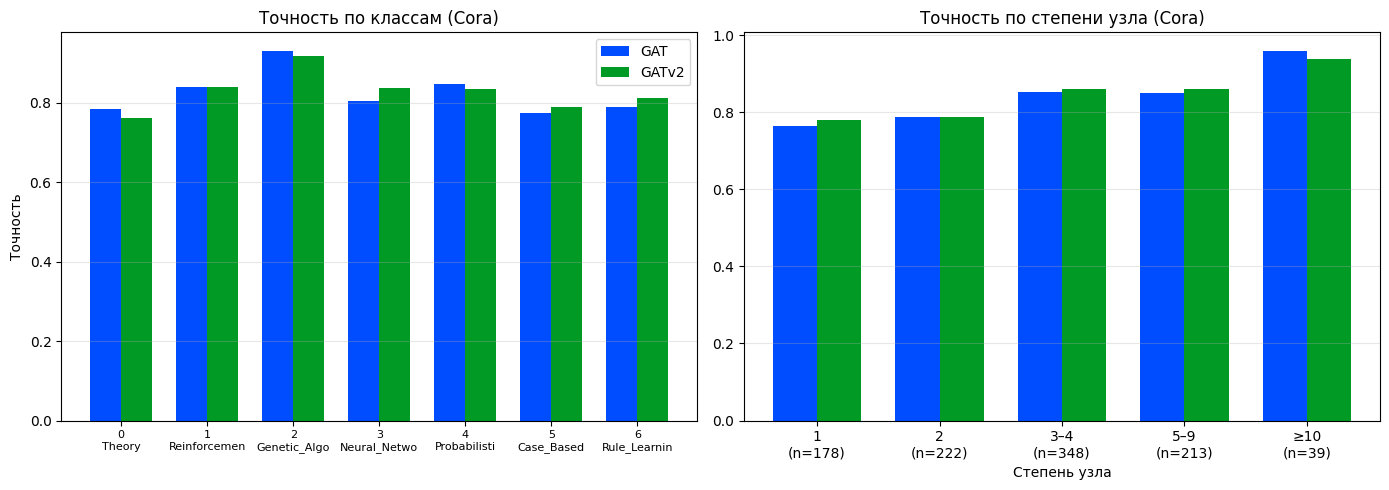

In [12]:
def plot_errors():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.arange(len(CORA_CLASSES))
    pc = RESULTS["errors"]["per_class"]
    axes[0].bar(x - 0.18, [pc[c]["GAT"] for c in CORA_CLASSES], 0.36, label="GAT", color="#004CFF")
    axes[0].bar(x + 0.18, [pc[c]["GATv2"] for c in CORA_CLASSES], 0.36, label="GATv2", color="#009A24")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels([f"{i}\n{c[:12]}" for i, c in enumerate(CORA_CLASSES)], fontsize=8)
    axes[0].set_ylabel("Точность")
    axes[0].set_title("Точность по классам (Cora)")
    axes[0].legend()
    axes[0].grid(axis="y", alpha=0.3)

    pd_ = RESULTS["errors"]["per_degree"]
    x = np.arange(len(DEG_LABELS))
    axes[1].bar(x - 0.18, [pd_[l]["GAT"] for l in DEG_LABELS], 0.36, label="GAT", color="#004CFF")
    axes[1].bar(x + 0.18, [pd_[l]["GATv2"] for l in DEG_LABELS], 0.36, label="GATv2", color="#009A24")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels([f"{l}\n(n={pd_[l]['n_test']})" for l in DEG_LABELS])
    axes[1].set_xlabel("Степень узла")
    axes[1].set_title("Точность по степени узла (Cora)")
    axes[1].grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig("figures/fig_errors.png", dpi=150)
    plt.show()


plot_errors()

## Эксперимент 5. Внимание обученных моделей на Cora

**Проверка статичности.** По теории (формула 7 РПЗ) в каждой голове GAT порядок важности соседей одинаков для всех целевых узлов. Для каждой головы первого слоя берутся все пары соседей (j, k), встречающиеся у нескольких целевых узлов, и считается доля пар, у которых порядок α_ij > α_ik меняется от узла к узлу. Для GAT ожидается 0, для GATv2 — больше 0.

**Равномерность.** Отношение энтропии весов узла к log(deg + 1): 1 означает равномерное внимание.

Важно: анализ ведётся **по отдельным головам** — после усреднения по головам статичность GAT уже не обязана сохраняться.

In [13]:
def attention_heads(model, data):
    with torch.no_grad():
        _, (ei, alpha) = model.conv1(data.x, data.edge_index, return_attention_weights=True)
    return ei.cpu(), alpha.cpu()  # alpha: [E, heads]


def rank_disagreement(ei, a, tol=1e-6):
    """Доля пар соседей (j, k), встречающихся у >= 2 целевых узлов,
    порядок которых (alpha_ij > alpha_ik или наоборот) различается у разных целевых узлов."""
    by_target = defaultdict(list)
    for (s, t), w in zip(ei.t().tolist(), a.tolist()):
        by_target[t].append((s, w))
    signs = defaultdict(set)     # (j, k) -> множество наблюдавшихся знаков
    counts = defaultdict(int)    # (j, k) -> у скольких целевых узлов встретилась пара
    for lst in by_target.values():
        lst.sort()
        for i in range(len(lst)):
            for j in range(i + 1, len(lst)):
                key = (lst[i][0], lst[j][0])
                counts[key] += 1
                d = lst[i][1] - lst[j][1]
                if abs(d) > tol:
                    signs[key].add(d > 0)
    shared = [k for k, c in counts.items() if c >= 2 and k in signs]
    if not shared:
        return float("nan"), 0
    flips = sum(len(signs[k]) == 2 for k in shared)
    return flips / len(shared), len(shared)


def norm_entropy(ei, a):
    t = ei[1]
    ent = torch.zeros(int(t.max()) + 1).scatter_add_(0, t, -a * torch.log(a.clamp_min(1e-12)))
    cnt = torch.bincount(t).float()
    mask = cnt >= 2
    return (ent[mask] / torch.log(cnt[mask])).mean().item()


RESULTS["attention"] = {}
for m in ["GAT", "GATv2"]:
    ei, alpha = attention_heads(trained[m], data_cora)
    dis, ent = [], []
    for h in range(alpha.size(1)):
        d, n_pairs = rank_disagreement(ei, alpha[:, h])
        dis.append(d)
        ent.append(norm_entropy(ei, alpha[:, h]))
    d_mean, n_pairs = rank_disagreement(ei, alpha.mean(1))
    RESULTS["attention"][m] = dict(
        rank_disagreement_per_head=[round(x, 4) for x in dis],
        rank_disagreement_head_mean=round(float(d_mean), 4),
        norm_entropy_per_head=[round(x, 4) for x in ent],
        shared_pairs=n_pairs)
    print(f"{m}: доля пар с разным порядком по головам: {np.round(dis, 4)}")
    print(f"     то же после усреднения по головам: {d_mean:.4f}   (пар: {n_pairs})")
    print(f"     нормированная энтропия по головам: {np.round(ent, 3)}")

GAT: доля пар с разным порядком по головам: [0. 0. 0. 0. 0. 0. 0. 0.]
     то же после усреднения по головам: 0.0602   (пар: 8738)
     нормированная энтропия по головам: [1. 1. 1. 1. 1. 1. 1. 1.]
GATv2: доля пар с разным порядком по головам: [0.0128 0.01   0.0177 0.0206 0.0172 0.0142 0.0164 0.0124]
     то же после усреднения по головам: 0.0146   (пар: 8738)
     нормированная энтропия по головам: [1.    0.999 0.999 1.    0.999 0.999 0.999 0.999]


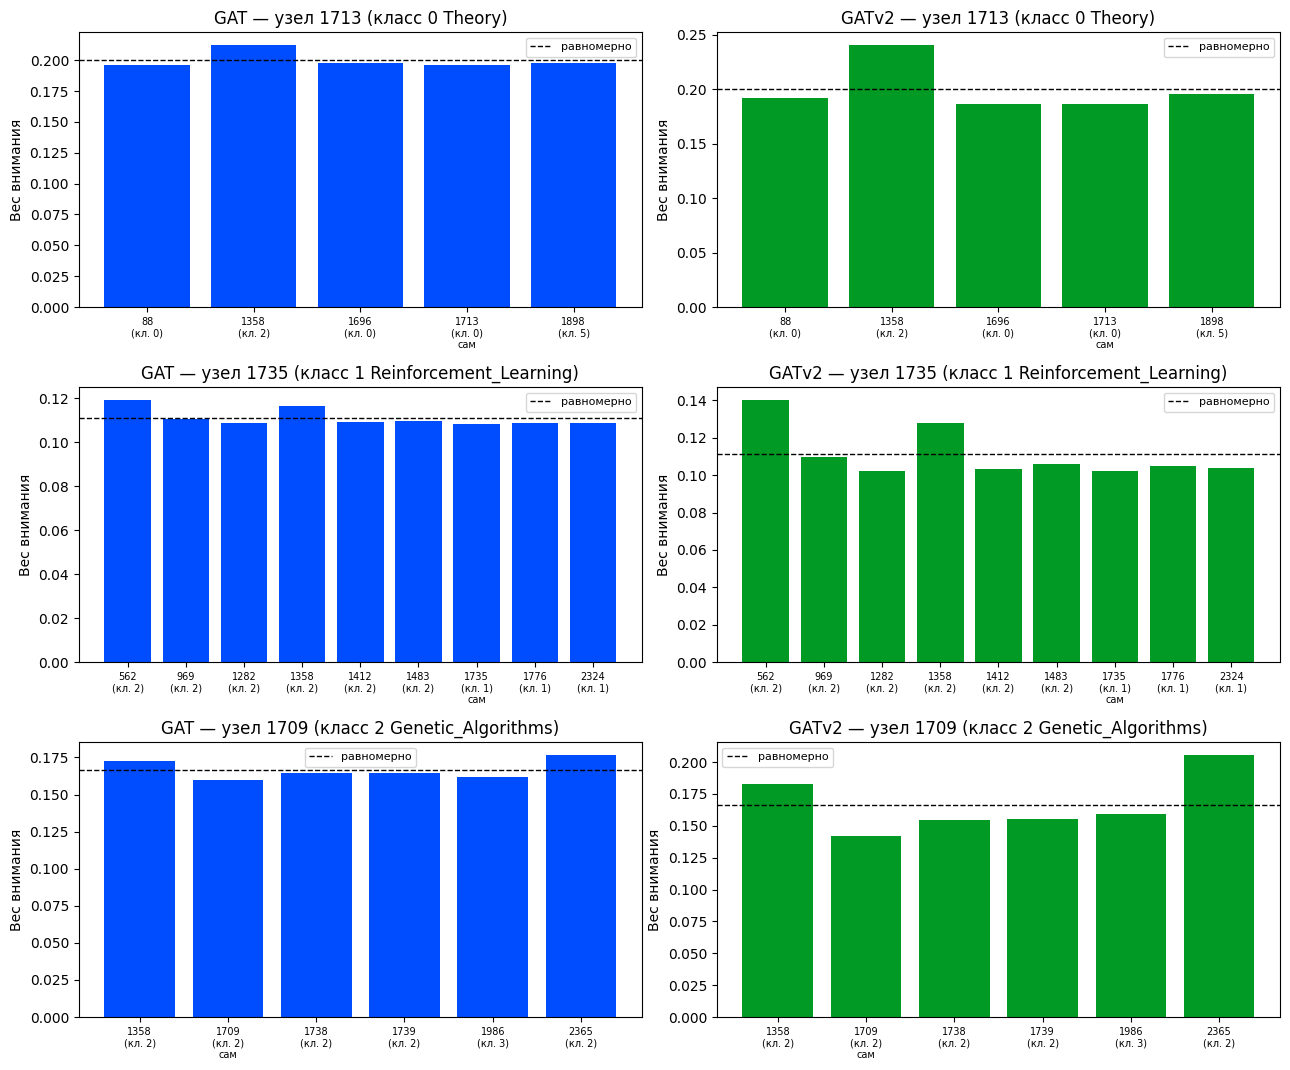

In [14]:
def plot_node_attention(nodes):
    fig, axes = plt.subplots(len(nodes), 2, figsize=(13, 3.6 * len(nodes)))
    y = data_cora.y.cpu()
    for row, node in enumerate(nodes):
        for col, (m, c) in enumerate([("GAT", "#004CFF"), ("GATv2", "#009A24")]):
            ei, alpha = attention_heads(trained[m], data_cora)
            mask = ei[1] == node
            nb, w = ei[0][mask].tolist(), alpha.mean(1)[mask].tolist()
            order = np.argsort(nb)
            labels = [f"{nb[i]}\n(кл. {y[nb[i]].item()})" + ("\nсам" if nb[i] == node else "") for i in order]
            ax = axes[row, col]
            ax.bar(range(len(nb)), [w[i] for i in order], color=c)
            ax.axhline(1 / len(nb), color="k", linestyle="--", linewidth=1, label="равномерно")
            ax.set_xticks(range(len(nb)))
            ax.set_xticklabels(labels, fontsize=7)
            ax.set_title(f"{m} — узел {node} (класс {y[node].item()} {CORA_CLASSES[y[node]]})")
            ax.set_ylabel("Вес внимания")
            ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig("figures/fig_attention_cora.png", dpi=150)
    plt.show()


plot_node_attention([1713, 1735, 1709])

## Эксперимент 6. Синтетическая задача DictionaryLookup (с обучением)

Задача из статьи GATv2 (Brody et al., 2022). Граф — полный двудольный: k узлов-«ключей» и k узлов-«запросов». У ключа есть атрибут (имя) и значение, у запроса — только атрибут. Каждый запрос соединён со всеми ключами. Метка запроса — значение того ключа, чей атрибут совпадает с атрибутом запроса.

Чтобы решить задачу, каждый запрос должен «смотреть» на **свой** ключ, то есть у разных запросов самым важным должен оказаться разный сосед. Статическое внимание GAT этого сделать не может (порядок соседей одинаков для всех запросов), динамическое внимание GATv2 — может.

In [15]:
K = 10        # число ключей и запросов
EMB = 64


def make_lookup_batch(batch, k=K, gen=None):
    attr_q = torch.stack([torch.randperm(k, generator=gen) for _ in range(batch)])   # [B, k]
    values = torch.randint(0, k, (batch, k), generator=gen)                          # значения ключей
    n = 2 * k
    key_attr = torch.arange(k).repeat(batch, 1)
    attr = torch.cat([key_attr, attr_q], 1).reshape(-1)
    val = torch.cat([values, torch.full((batch, k), k)], 1).reshape(-1)              # k — «нет значения»
    off = (torch.arange(batch) * n).view(-1, 1, 1)
    src = (torch.arange(k).view(1, k, 1).expand(batch, k, k) + off).reshape(-1)
    dst = (torch.arange(k, 2 * k).view(1, 1, k).expand(batch, k, k) + off).reshape(-1)
    edge_index = torch.stack([src, dst])
    is_query = torch.cat([torch.zeros(batch, k), torch.ones(batch, k)], 1).reshape(-1).bool()
    y = torch.gather(values, 1, attr_q).reshape(-1)                                  # ответ для запроса
    return attr, val, edge_index, is_query, y


class LookupNet(torch.nn.Module):
    def __init__(self, v2, k=K, d=EMB):
        super().__init__()
        self.emb_attr = torch.nn.Embedding(k, d)
        self.emb_val = torch.nn.Embedding(k + 1, d)
        Conv = GATv2Conv if v2 else GATConv
        self.conv = Conv(d, d, heads=1, add_self_loops=False)
        self.out = torch.nn.Linear(d, k)

    def forward(self, attr, val, edge_index, return_att=False):
        x = self.emb_attr(attr) + self.emb_val(val)
        h, (ei, a) = self.conv(x, edge_index, return_attention_weights=True)
        out = self.out(F.relu(h))
        return (out, ei, a) if return_att else out


def train_lookup(v2, steps=3000, batch=64, seed=0):
    set_seed(seed)
    model = LookupNet(v2).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(seed)
    hist = []
    for step in range(steps):
        attr, val, ei, q, y = [t.to(device) for t in make_lookup_batch(batch, gen=gen)]
        model.train()
        opt.zero_grad()
        out = model(attr, val, ei)
        loss = F.cross_entropy(out[q], y)
        loss.backward()
        opt.step()
        if step % 100 == 0 or step == steps - 1:
            hist.append((step, (out[q].argmax(1) == y).float().mean().item()))
    return model, hist


def eval_lookup(model, n_batches=20, batch=64, seed=123):
    gen = torch.Generator().manual_seed(seed)
    model.eval()
    acc, att_ok = [], []
    with torch.no_grad():
        for _ in range(n_batches):
            attr, val, ei, q, y = [t.to(device) for t in make_lookup_batch(batch, gen=gen)]
            out, ei_, a = model(attr, val, ei, return_att=True)
            acc.append((out[q].argmax(1) == y).float().mean().item())
            # доля запросов, у которых наибольший вес получил «свой» ключ
            a = a.view(-1)
            src_attr, dst_attr = attr[ei_[0]], attr[ei_[1]]
            dst = ei_[1]
            best = torch.full((attr.numel(),), -1.0, device=a.device).scatter_reduce(0, dst, a, "amax")
            is_best = a >= best[dst] - 1e-9
            right = is_best & (src_attr == dst_attr)
            att_ok.append(right.sum().item() / q.sum().item())
    return float(np.mean(acc)), float(np.mean(att_ok))


RESULTS["lookup"] = {}
lookup_models = {}
for name, v2 in [("GAT", False), ("GATv2", True)]:
    model, hist = train_lookup(v2)
    acc, att = eval_lookup(model)
    lookup_models[name] = (model, hist)
    RESULTS["lookup"][name] = dict(test_acc=round(acc, 4), attention_on_correct_key=round(att, 4),
                                   final_train_acc=round(hist[-1][1], 4))
    print(f"{name}: точность на новых графах {acc:.3f}; "
          f"доля запросов, где max внимания — на нужном ключе: {att:.3f}  "
          f"(случайное угадывание: {1 / K:.3f})")

GAT: точность на новых графах 0.305; доля запросов, где max внимания — на нужном ключе: 0.100  (случайное угадывание: 0.100)
GATv2: точность на новых графах 1.000; доля запросов, где max внимания — на нужном ключе: 1.000  (случайное угадывание: 0.100)


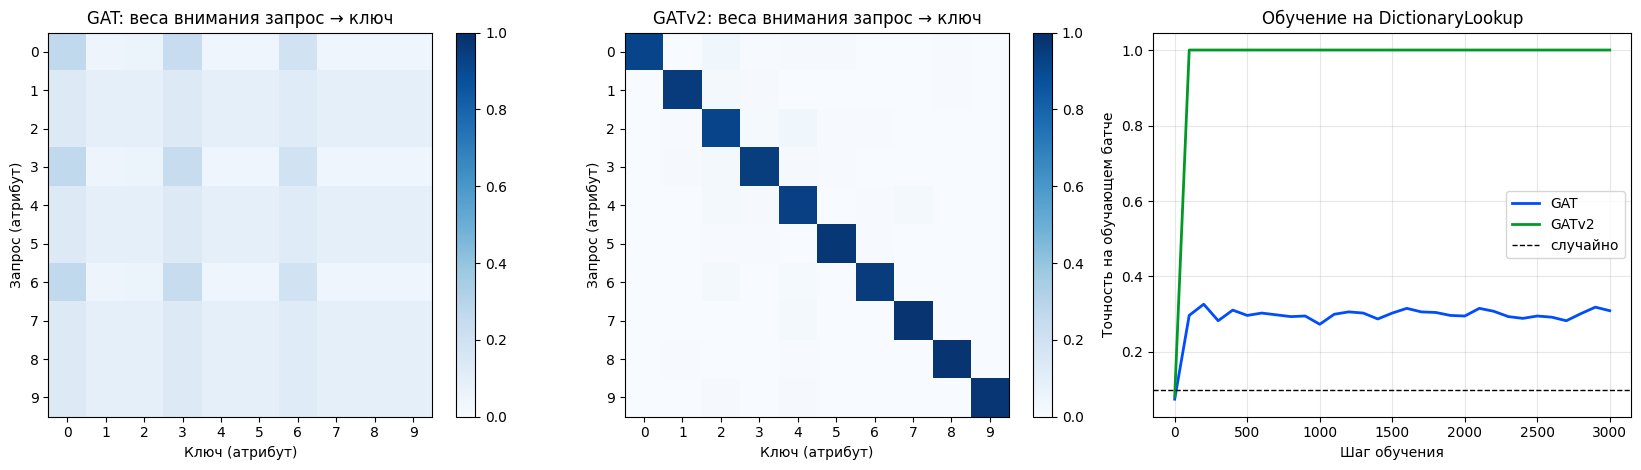

In [16]:
def plot_lookup():
    gen = torch.Generator().manual_seed(7)
    attr, val, ei, q, y = [t.to(device) for t in make_lookup_batch(1, gen=gen)]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    for ax, name in zip(axes[:2], ["GAT", "GATv2"]):
        model = lookup_models[name][0]
        with torch.no_grad():
            _, ei_, a = model(attr, val, ei, return_att=True)
        M = np.zeros((K, K))
        for (s, t), w in zip(ei_.t().tolist(), a.view(-1).tolist()):
            M[t - K, s] = w
        # строки — запросы, отсортированы по атрибуту; столбцы — ключи (атрибут = номер ключа)
        order = np.argsort(attr[K:2 * K].cpu().numpy())
        im = ax.imshow(M[order], cmap="Blues", vmin=0, vmax=1)
        ax.set_xlabel("Ключ (атрибут)")
        ax.set_ylabel("Запрос (атрибут)")
        ax.set_title(f"{name}: веса внимания запрос → ключ")
        ax.set_xticks(range(K))
        ax.set_yticks(range(K))
        plt.colorbar(im, ax=ax, fraction=0.046)
    for name, c in [("GAT", "#004CFF"), ("GATv2", "#009A24")]:
        h = np.array(lookup_models[name][1])
        axes[2].plot(h[:, 0], h[:, 1], color=c, label=name, linewidth=2)
    axes[2].axhline(1 / K, color="k", linestyle="--", linewidth=1, label="случайно")
    axes[2].set_xlabel("Шаг обучения")
    axes[2].set_ylabel("Точность на обучающем батче")
    axes[2].set_title("Обучение на DictionaryLookup")
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("figures/fig_lookup.png", dpi=150)
    plt.show()


plot_lookup()

Для правильного решения матрица GATv2 должна быть близка к диагональной (каждый запрос смотрит на ключ со своим атрибутом). У GAT во всех строках максимум приходится на один и тот же столбец — это и есть статическое внимание.

## Сохранение результатов

In [17]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o


with open("results.json", "w", encoding="utf-8") as f:
    json.dump(to_jsonable(RESULTS), f, ensure_ascii=False, indent=1)
print("Результаты сохранены в results.json; рисунки — в папке figures/")

Результаты сохранены в results.json; рисунки — в папке figures/
